#### STEP 1: IMPORT LIBRARIES

In [2]:
#import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import openpyxl

#### STEP 2: LOAD DATASET

In [3]:
#read the excel file
patients = pd.read_excel('patient_records_dataset.xlsx')
patients.head(10)

,patient_id,date_of_birth,gender,height_cm,weight_kg,blood_type,systolic_bp_mmHg,diastolic_bp_mmHg,fasting_blood_sugar_mg_dl,cholesterol_mg_dl,daily_salt_intake_g,activity_hours_per_week,smoker_status,hypertension_diagnosis
0,PAT-1001,1946-03-17,Male,166.5,80.2,O+,164,97,113.0,244.7,13.2,0,Non-Smoker,1
1,PAT-1002,1992-05-08,Female,156.8,57.8,O+,137,85,97.6,178.5,9.5,1,Non-Smoker,1
2,PAT-1003,1976-04-11,Female,165.9,85.9,O+,143,81,107.5,184.8,12.1,3,Non-Smoker,1
3,PAT-1004,1980-03-03,Female,153.7,69.6,A+,136,82,107.1,225.2,6.7,2,Non-Smoker,0
4,PAT-1005,1996-10-27,Male,180.9,89.0,O+,143,85,104.0,174.4,8.0,10,Former Smoker,1
5,PAT-1006,1963-05-06,Male,164.2,74.9,A+,161,102,107.5,210.9,11.6,1,Non-Smoker,1
6,PAT-1007,1974-11-09,Male,180.3,121.0,AB-,152,91,108.0,231.1,7.6,1,Non-Smoker,1
7,PAT-1008,2003-08-06,Female,NaN,72.5,A+,137,78,109.0,195.5,10.1,0,Non-Smoker,1
8,PAT-1009,1962-11-09,Female,157.7,94.5,A+,148,91,122.8,257.2,5.2,0,Former Smoker,1
9,PAT-1010,1984-04-07,Female,175.3,91.1,A+,147,92,107.0,185.2,10.2,1,Non-Smoker,1


#### STEP 3: DATA INSPECTION

In [4]:
#data summary
patients.describe()

,date_of_birth,height_cm,weight_kg,systolic_bp_mmHg,diastolic_bp_mmHg,fasting_blood_sugar_mg_dl,cholesterol_mg_dl,daily_salt_intake_g,activity_hours_per_week,hypertension_diagnosis
count,500,495.000000,500.000000,500.000000,500.000000,500.000000,500.000000,500.000000,500.000000,500.000000
mean,1975-09-02 04:22:04.800000,167.969293,77.350400,144.128000,89.238000,111.795200,209.033000,9.216200,1.740000,0.790000
min,1941-01-05 00:00:00,138.500000,36.000000,117.000000,71.000000,78.200000,144.700000,3.000000,0.000000,0.000000
25%,1958-06-01 18:00:00,160.950000,64.975000,137.000000,84.000000,103.475000,191.175000,6.300000,0.000000,1.000000
50%,1975-12-06 12:00:00,167.000000,76.350000,144.000000,89.000000,111.800000,206.400000,9.600000,1.000000,1.000000
75%,1992-10-13 18:00:00,174.750000,88.600000,151.000000,95.000000,120.200000,221.950000,12.225000,3.000000,1.000000
max,2008-11-14 00:00:00,196.600000,125.600000,171.000000,113.000000,149.000000,380.600000,15.000000,10.000000,1.000000
std,NaN,9.981949,16.479724,9.957405,7.651827,12.233453,30.118047,3.452581,1.700053,0.407716


In [5]:
#check data information
patients.info()

<class 'pandas.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 14 columns):
 #   Column                     Non-Null Count  Dtype         
---  ------                     --------------  -----         
 0   patient_id                 500 non-null    str           
 1   date_of_birth              500 non-null    datetime64[us]
 2   gender                     500 non-null    str           
 3   height_cm                  495 non-null    float64       
 4   weight_kg                  500 non-null    float64       
 5   blood_type                 498 non-null    str           
 6   systolic_bp_mmHg           500 non-null    int64         
 7   diastolic_bp_mmHg          500 non-null    int64         
 8   fasting_blood_sugar_mg_dl  500 non-null    float64       
 9   cholesterol_mg_dl          500 non-null    float64       
 10  daily_salt_intake_g        500 non-null    float64       
 11  activity_hours_per_week    500 non-null    int64         
 12  smoker_status      

In [6]:
patients.shape

(500, 14)

In [7]:
patients.columns

Index(['patient_id', 'date_of_birth', 'gender', 'height_cm', 'weight_kg',
       'blood_type', 'systolic_bp_mmHg', 'diastolic_bp_mmHg',
       'fasting_blood_sugar_mg_dl', 'cholesterol_mg_dl', 'daily_salt_intake_g',
       'activity_hours_per_week', 'smoker_status', 'hypertension_diagnosis'],
      dtype='str')

In [8]:
#check for duplicates
patients.duplicated().sum()

np.int64(0)

In [9]:
#check for missing values
patients.isna().sum()

patient_id                   0
date_of_birth                0
gender                       0
height_cm                    5
weight_kg                    0
blood_type                   2
systolic_bp_mmHg             0
diastolic_bp_mmHg            0
fasting_blood_sugar_mg_dl    0
cholesterol_mg_dl            0
daily_salt_intake_g          0
activity_hours_per_week      0
smoker_status                0
hypertension_diagnosis       0
dtype: int64

#### Observation: 
- The dataset has 500 rows and 14 columns. 
- There are no Duplicates. 
- There are total of 7 missing values.
- The height_cm and blood_type columns has missing values.(height_cm:5, blood_type:2). 

#### STEP 4: DATA CLEANING
- Fill the missing values: there is a major natural factor that contributes to the height of an individual which is "gender". It would be more justifiable, and show more logical reasoning to split the dataset by their gender before calculating their measures of central tendencies.
- For the blood_type column: having that the column is delicate, the missing values will be filled with 'UNKNOWN'
- Check for outlier and skewness 

In [ ]:
#find the mean, median and mode of the columns with missing values to determine the methods that would be used in filling them.
print('mean:', patients['height_cm'].mean())
print('median:', patients['height_cm'].median())
print('mode:', patients['height_cm'].mode()[0])

mean: 167.96929292929292
median: 167.0
mode: 164.2


In [17]:
#find the median of the gender column
gender_median = patients.groupby('gender')['height_cm'].median()
print(gender_median)

gender
Female    162.2
Male      174.9
Name: height_cm, dtype: float64


In [16]:
patients.loc[patients['height_cm'].isnull(), ['gender', 'height_cm']]

,gender,height_cm
7,Female,NaN
42,Male,NaN
52,Female,NaN
65,Female,NaN
87,Female,NaN


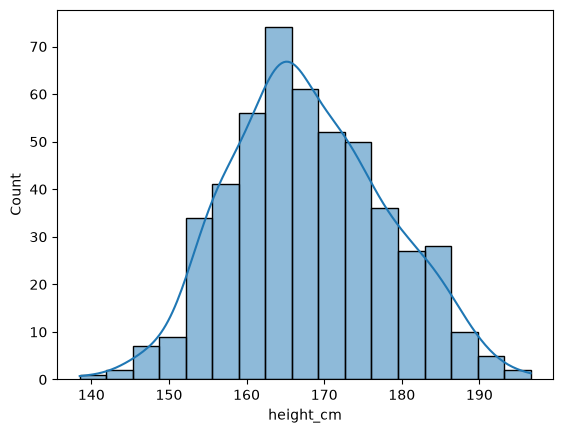

In [11]:
#check for skewness in height_cm column

sns.histplot(data = patients, x = 'height_cm', kde=True)
plt.show()

#### Observation:The column is right-skewed.

Does the column 'height_cm' have an outlier?

In [12]:
#calculate the quantiles so as to determine if there are outliers
Q1 = patients['height_cm'].quantile(0.25)
Q3 = patients['height_cm'].quantile(0.75)
IQR = Q3 - Q1
print(f'Q1: {Q1}')
print(f'Q3: {Q3}')
print(f'IQR: {IQR}')

Q1: 160.95
Q3: 174.75
IQR: 13.800000000000011


In [13]:
#find the lower bound and the upper bound limits
lower_bound = Q1 - (1.5 * IQR)
upper_bound = Q3 + (1.5 * IQR)
print(f'lower_bound: {lower_bound}')
print(f'upper_bound: {upper_bound}')

lower_bound: 140.24999999999997
upper_bound: 195.45000000000002


In [14]:
#identify outlier
outlier = patients[(patients['height_cm'] < lower_bound) | (patients['height_cm'] > upper_bound)]
print(outlier)

    patient_id date_of_birth  gender  height_cm  weight_kg blood_type  \
135   PAT-1136    2002-02-14    Male      196.6       88.8         B+   
271   PAT-1272    1942-01-15  Female      138.5       59.3         B+   

     systolic_bp_mmHg  diastolic_bp_mmHg  fasting_blood_sugar_mg_dl  \
135               132                 79                       96.9   
271               168                104                      123.2   

     cholesterol_mg_dl  daily_salt_intake_g  activity_hours_per_week  \
135              206.4                 11.2                        1   
271              245.5                 12.4                        1   

     smoker_status  hypertension_diagnosis  
135     Non-Smoker                       0  
271  Former Smoker                       1  


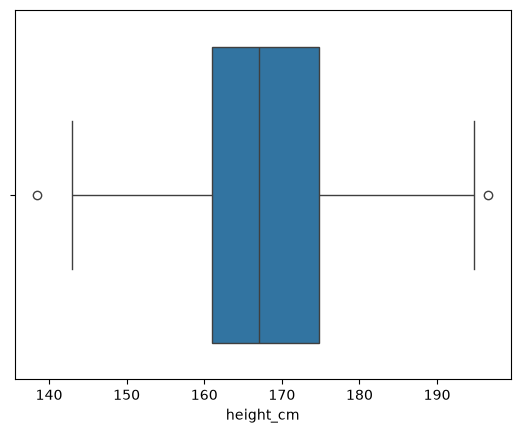

In [15]:
sns.boxplot(data=patients, x='height_cm')
plt.show()

#### Observation:
- The column has an outlier and it's partially right-skewed. 
- Because of outlier and the distribution of column, median is being considered in filling the missing values.
- The column blood_type is categorical, and it will be filled with 'UNKNOWN' as it's a delicate column

In [18]:
#fill the height_cm column using the corresponding gender median

patients['height_cm'] = patients['height_cm'].fillna(patients['gender'].map(gender_median))
print(patients['height_cm'].isna().sum())

0


In [19]:
#fill the blood type column with mode; this is because the column is numerical
patients.fillna({'blood_type': 'UNKNOWN'}, inplace=True)
print(patients['blood_type'].isna().sum())

0


#### STEP 5: DATA VISUALIZATION - BOX PLOT ANALYSIS

- Check the smoker_status column to understand its distribution by plotting a pie chart

In [19]:
smoker_status = patients['smoker_status'].value_counts()
smoker_status.values

array([317, 121,  62])

In [20]:
smoker_status.index

Index(['Non-Smoker', 'Former Smoker', 'Current Smoker'], dtype='str', name='smoker_status')

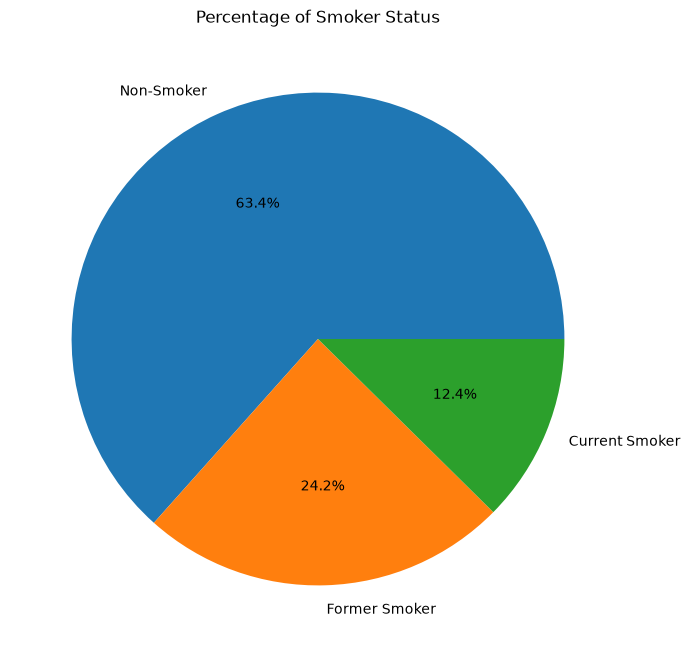

In [21]:
plt.figure(figsize=(12, 8))

plt.pie(x = smoker_status.values, labels = smoker_status.index, autopct='%1.1f%%')
plt.title('Percentage of Smoker Status')
plt.show()

- Create a box plot of cholesterol_mg_dl grouped by smoker_status. Identify the 
upper whisker bound, median line, and count how many extreme outliers exist 
above 1. 5 × 𝐼𝑄𝑅

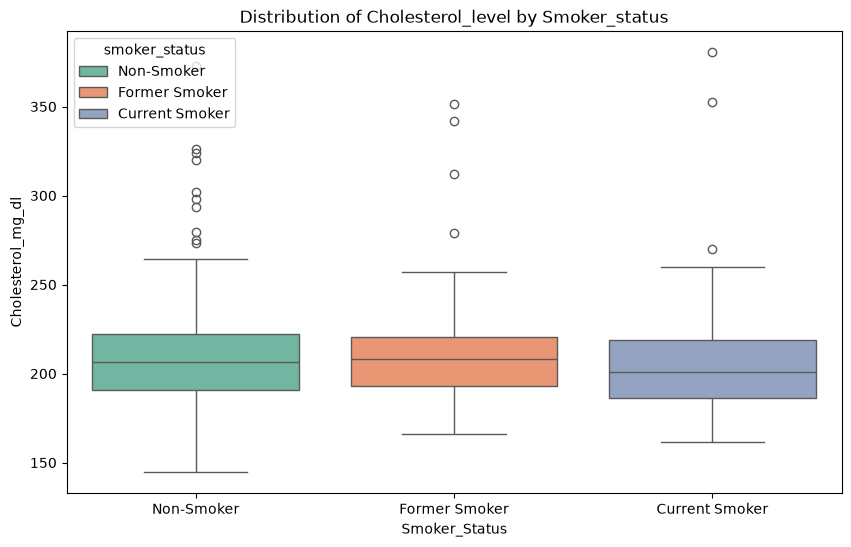

In [22]:
plt.figure(figsize=(10, 6))
sns.boxplot(data = patients, y = 'cholesterol_mg_dl', x = 'smoker_status', hue = 'smoker_status', palette = 'Set2', legend = True)

plt.title('Distribution of Cholesterol_level by Smoker_status')
plt.xlabel('Smoker_Status')
plt.ylabel('Cholesterol_mg_dl')
plt.show()

In [23]:
#calculate the Q1 for the distribution of cholesterol level by smoker status
cholesterol_level = patients.groupby('smoker_status')['cholesterol_mg_dl']
c_smoker_Q1 = cholesterol_level.quantile(0.25)
c_smoker_Q1

smoker_status
Current Smoker    186.225
Former Smoker     192.900
Non-Smoker        190.900
Name: cholesterol_mg_dl, dtype: float64

In [24]:
cholesterol_level.describe()

,count,mean,std,min,25%,50%,75%,max
smoker_status,,,,,,,,
Current Smoker,62.0,208.864516,37.735638,161.6,186.225,200.85,219.075,380.6
Former Smoker,121.0,210.711570,29.592486,166.3,192.900,208.10,220.300,351.4
Non-Smoker,317.0,208.425237,28.697076,144.7,190.900,206.70,222.400,372.5


In [25]:
#calculate the Q3 for the distribution of cholesterol level by smoker status
c_smoker_Q3 = cholesterol_level.quantile(0.75)
c_smoker_Q3

smoker_status
Current Smoker    219.075
Former Smoker     220.300
Non-Smoker        222.400
Name: cholesterol_mg_dl, dtype: float64

In [26]:
#calculate the IQR
c_smoker_IQR = c_smoker_Q3 - c_smoker_Q1
c_smoker_IQR

smoker_status
Current Smoker    32.85
Former Smoker     27.40
Non-Smoker        31.50
Name: cholesterol_mg_dl, dtype: float64

In [27]:
#calculate the upper bound
c_smoker_upper = c_smoker_Q3 + (1.5 * c_smoker_IQR)
c_smoker_upper

smoker_status
Current Smoker    268.35
Former Smoker     261.40
Non-Smoker        269.65
Name: cholesterol_mg_dl, dtype: float64

In [28]:
#calculate the lower bound
c_smoker_lower = c_smoker_Q1 - (1.5 * c_smoker_IQR)
c_smoker_lower

smoker_status
Current Smoker    136.95
Former Smoker     151.80
Non-Smoker        143.65
Name: cholesterol_mg_dl, dtype: float64

#### Observation:
- The upper whisker bound (Non-smoker: 269.65, Former-Smoker: 261.40, Current-Smoker: 268.35)
- The median line (Non-smoker: 206.70, Former-Smoker: 208.10, Current-Smoker: 200.85)
- There are 17 outliers in total which Non-Smoker had the highest outlier. (Note: Non-smoker category had the highest distribution by 63.4% than other categories which must have also contributed to its high number of outliers.)

-  Construct side-by-side box plots for systolic_bp_mmHg broken down by hypertension_diagnosis (0 vs 1). What does the overlap/separation between  the two boxes indicate about blood pressure as a feature? 

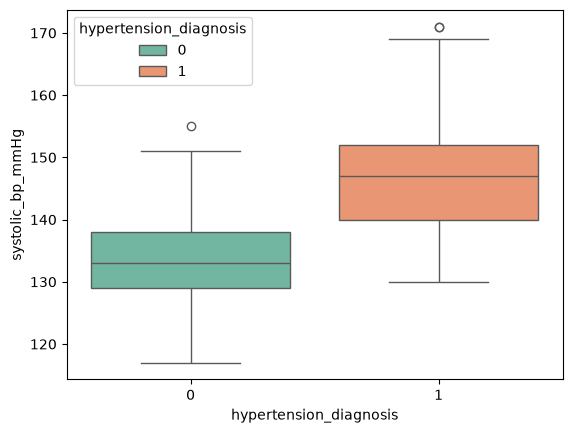

In [29]:
sns.boxplot(data=patients, y='systolic_bp_mmHg', x='hypertension_diagnosis', hue = 'hypertension_diagnosis', palette = 'Set2', legend = True)

plt.show()

#### Observation:
- There's no overlap between the two groups.
- In group 0, it shows that most patients systolic level falls within 129 to 139 mmHg.
- In group 1, it shows that most patients systolic level falls withing 140 to 152 mmHg.
- It shows that most patients in group 1 has higher systolic level which means that systolic_bp_mmHg strongly contributes to hypertension_diagnosis as a feature.

- What factors contribute to the hypertension diagnosis of the patients in the dataset? 

#### STEP 6: CORRELATION ANALYSIS

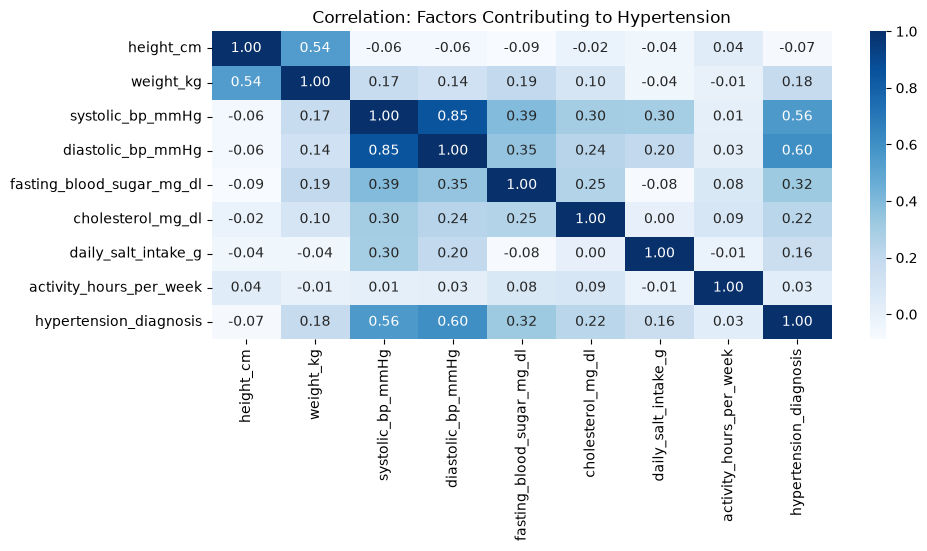

In [30]:
#create a correlation heatmap

corr = patients.corr(numeric_only=True, method= 'pearson')

plt.figure(figsize=(10, 4))
sns.heatmap(corr, cmap = 'Blues', annot=True, fmt = '.2f')
plt.title('Correlation: Factors Contributing to Hypertension')
plt.show()

#### Observation:
- the factors that can contribute to hypertension diagnosis are; systolic_bp_mmHg, diastolic_bp_mmHg, fasting_blood_sugar_mg_dl, cholesterol_mg_dl, weight_kg, daily_salt_intake_g

- Plot a scatter plot of systolic_bp_mmHg vs diastolic_bp_mmHg colored by hypertension_diagnosis. Draw a trendline. 
- How can continuous predictors be used to train a logistic regression or decision tree model?

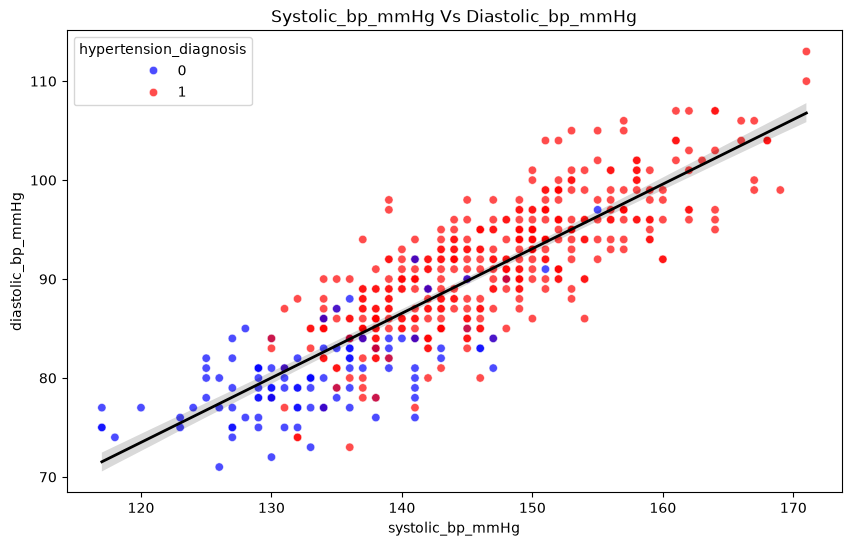

In [31]:
plt.figure(figsize=(10, 6))

sns.scatterplot(data = patients, x = 'systolic_bp_mmHg', y = 'diastolic_bp_mmHg', hue = 'hypertension_diagnosis', palette = {0: 'blue', 1: 'red'}, alpha = 0.7)

#add a trendline
sns.regplot(data = patients, x = 'systolic_bp_mmHg', y = 'diastolic_bp_mmHg', scatter = False, color = 'black', line_kws = {'linewidth': 2})
plt.title('Systolic_bp_mmHg Vs Diastolic_bp_mmHg')
plt.show()

#### Observation
- There's a positive correlation between the systolic and diastolic. (As the systolic_bp_mmHg increases, diastolic_bp_mmHg increases)